# 02 — Meu primeiro backtest: cruzamento de médias móveis no EURUSD

**LHS Quant Lab** · notebook didático

## O que é um backtest?
Um **backtest** é uma simulação: pegamos uma regra de operação escrita de forma objetiva
("compre quando X, venda quando Y") e aplicamos essa regra nos **preços do passado**, barra por barra,
como se estivéssemos operando naquela época. No fim medimos quanto a estratégia teria ganhado ou perdido,
quanto ela sofreu no caminho (drawdown) e se ela é melhor do que alternativas simples.

> Um backtest **não prevê o futuro**. Ele responde: *"se eu tivesse seguido essa regra, sem desvio,
> com esses custos, o que teria acontecido?"*. Serve para descartar ideias ruins rápido e
> desconfiar das boas.

## O que este backtest testa
**Pergunta:** *seguir a tendência do EURUSD com um cruzamento de médias móveis no gráfico de 4 horas (H4)
dá lucro depois de pagar spread e slippage?*

## A estratégia: cruzamento de médias móveis (SMA 20 × SMA 50)
- **Média rápida** = média dos últimos 20 fechamentos (reage rápido ao preço).
- **Média lenta** = média dos últimos 50 fechamentos (mostra a tendência mais longa).
- **Regra:**
  - média rápida **acima** da lenta → tendência de alta → ficamos **comprados** (+1);
  - média rápida **abaixo** da lenta → tendência de baixa → ficamos **vendidos** (−1).
- Ficamos **sempre posicionados**: quando as médias cruzam, zeramos a posição e viramos para o outro lado
  ("stop and reverse"). Não há stop loss nem alvo fixo — a saída é o cruzamento contrário.

É a estratégia mais clássica de *trend following*. Ela ganha em tendências longas e perde em mercado
lateral (quando as médias ficam se cruzando para lá e para cá — o famoso *whipsaw*).

## Roteiro do notebook
1. Configuração (parâmetros em um só lugar)
2. Carregar os dados
3. Calcular os indicadores
4. Gerar o sinal **sem olhar o futuro**
5. Calcular retornos e **custos**
6. Curva de capital e drawdown
7. Lista de operações (trades)
8. Métricas de desempenho
9. Comparação com baselines (buy & hold e sinal aleatório)
10. In-sample × out-of-sample
11. Sensibilidade dos parâmetros
12. Salvar os resultados
13. Conclusões e exercícios

## 1. Configuração
Tudo o que pode mudar fica **nesta célula**. Assim, para testar outro par ou outras médias,
você só mexe aqui e roda o notebook inteiro de novo (*Run All*).

- `SIMBOLO` / `TIMEFRAME`: qual arquivo de dados ler (`dados/xm/EURUSD/H4.parquet`).
- `MEDIA_RAPIDA` / `MEDIA_LENTA`: períodos das médias.
- `SLIPPAGE_PONTOS`: escorregão estimado na execução, em **pontos** (no EURUSD, 1 ponto = 0,00001; 10 pontos = 1 pip).
- `COMISSAO_PCT`: comissão por operação completa (ida + volta). Na conta Standard da XM é 0 — o custo já vem no spread.
- `DATA_INICIO`: a partir de quando usar os dados (o H4 da XM vem desde 1971, mas o histórico antigo tem qualidade e spread pouco confiáveis).
- `DATA_CORTE`: separa o período de **estudo** (in-sample) do período de **validação** (out-of-sample).
- `SEED`: semente do gerador aleatório, para o baseline aleatório dar sempre o mesmo resultado.

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- parâmetros do teste ----------------
SIMBOLO = "EURUSD"
TIMEFRAME = "H4"
MEDIA_RAPIDA = 20
MEDIA_LENTA = 50

SLIPPAGE_PONTOS = 2  # por lado (entrada e saída)
COMISSAO_PCT = 0.0  # % por operação completa (ida+volta); XM Standard = 0
CAPITAL_INICIAL = 10_000  # USD, só para visualizar a curva
DATA_INICIO = (
    "2010-01-01"  # descarta o histórico muito antigo (spread/qualidade duvidosos)
)
DATA_CORTE = "2020-01-01"  # antes = in-sample, depois = out-of-sample
SEED = 42

RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"

plt.rcParams.update(
    {
        "figure.figsize": (12, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 2. Carregar os dados
Os candles vêm do banco Parquet montado no notebook `01_motor_de_dados` (puxados do MT5 da XM).
Cada linha é uma barra de 4 horas com: abertura, máxima, mínima, fechamento, volume de ticks e **spread**
(em pontos) daquela barra. Também lemos `info_simbolos.parquet` para saber o tamanho do **ponto** do par.

Depois de carregar, fazemos checagens básicas: período coberto, número de barras, se há datas
duplicadas ou preços faltando. **Dado ruim = backtest ruim**, então sempre olhe isso primeiro.

In [8]:
df = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{TIMEFRAME}.parquet").sort_index()
df = df.loc[DATA_INICIO:].copy()
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
PONTO = float(info.loc[info["simbolo"] == SIMBOLO, "ponto"].iloc[-1])

print(
    f"{SIMBOLO} {TIMEFRAME}: {len(df):,} barras de {df.index[0]:%Y-%m-%d} a {df.index[-1]:%Y-%m-%d}"
)
print(f"Tamanho do ponto: {PONTO}")
print(
    f"Datas duplicadas: {df.index.duplicated().sum()} | fechamentos vazios: {df['fechamento'].isna().sum()}"
)
print(
    f"Spread mediano: {df['spread'].median():.0f} pontos ({df['spread'].median() / 10:.1f} pips)"
)
df.tail(3)

EURUSD H4: 26,119 barras de 2010-01-04 a 2026-10-16
Tamanho do ponto: 1e-05
Datas duplicadas: 0 | fechamentos vazios: 0
Spread mediano: 16 pontos (1.6 pips)


,abertura,maxima,minima,fechamento,tick_volume,spread,real_volume
tempo,,,,,,,
2026-10-16 08:00:00,1.1228,1.1248,1.1219,1.1244,10795,16,0
2026-10-16 12:00:00,1.1244,1.1268,1.1240,1.1242,11669,16,0
2026-10-16 16:00:00,1.1242,1.1261,1.1212,1.1219,16271,16,0


## 3. Indicadores: as duas médias móveis
`rolling(n).mean()` calcula a média dos últimos `n` fechamentos **incluindo a barra atual**.
Isso está correto, porque a barra atual **já fechou** quando olhamos para ela — o cuidado com o futuro
vem no próximo passo.

As primeiras 49 barras ficam sem média lenta (`NaN`), porque ainda não existem 50 fechamentos.
Nesse período a estratégia fica **fora do mercado**.

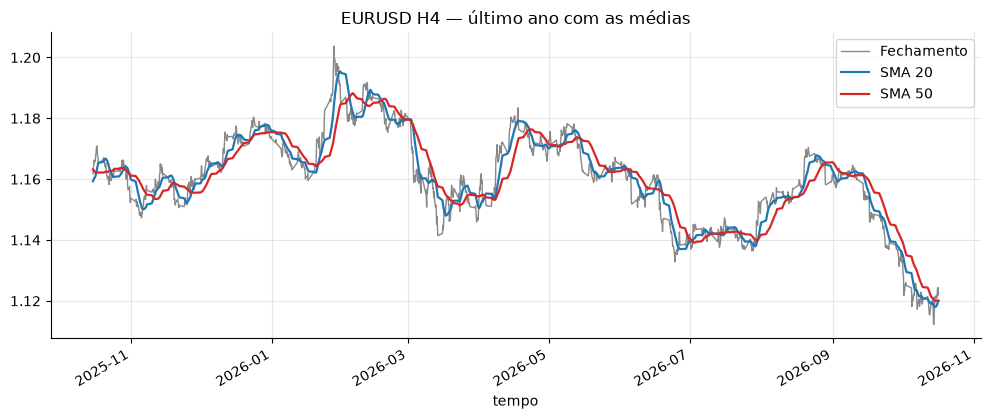

In [9]:
df["mm_rapida"] = df["fechamento"].rolling(MEDIA_RAPIDA).mean()
df["mm_lenta"] = df["fechamento"].rolling(MEDIA_LENTA).mean()

# Visualização: último ano de preço com as médias
recorte = df.iloc[-6 * 260 :]
ax = recorte["fechamento"].plot(color="#888", lw=1, label="Fechamento")
recorte["mm_rapida"].plot(ax=ax, color="#1f77b4", lw=1.6, label=f"SMA {MEDIA_RAPIDA}")
recorte["mm_lenta"].plot(ax=ax, color="#d62728", lw=1.6, label=f"SMA {MEDIA_LENTA}")
ax.set_title(f"{SIMBOLO} {TIMEFRAME} — último ano com as médias")
ax.legend()
plt.show()

## 4. Sinal e posição — a parte mais importante: **sem look-ahead**
**Look-ahead** (olhar o futuro) é o erro nº 1 de backtest: usar uma informação que você ainda não teria
no momento da decisão. Resultado: a estratégia parece genial no papel e quebra na conta real.

Como evitamos:
1. O **sinal** da barra *t* usa apenas o fechamento da barra *t* (já fechada): `+1` se rápida > lenta, `−1` se menor.
2. A **posição** que efetivamente carregamos durante a barra *t+1* é o sinal da barra *t* →
   `posicao = sinal.shift(1)`.

Ou seja: vemos o cruzamento no fechamento, **entramos no fechamento** daquela barra
(no forex, que é 24h, isso é praticamente a abertura da barra seguinte) e só ganhamos/perdemos
a partir da barra seguinte.

In [10]:
df["sinal"] = np.where(df["mm_rapida"] > df["mm_lenta"], 1, -1)
df.loc[df["mm_lenta"].isna(), "sinal"] = 0  # sem média ainda = fora

df["posicao"] = df["sinal"].shift(1).fillna(0)  # decide em t, carrega em t+1

contagem = (
    df["posicao"].value_counts().rename({1: "comprado", -1: "vendido", 0: "fora"})
)
print("Barras em cada estado:\n", (contagem / len(df)).map("{:.1%}".format).to_string())

Barras em cada estado:
 posicao
vendido     51.0%
comprado    48.8%
fora         0.2%


## 5. Retornos e custos
**Retorno do mercado** na barra *t*: variação percentual do fechamento, `fechamento_t / fechamento_{t-1} − 1`.

**Retorno bruto da estratégia** = posição × retorno do mercado. Comprado ganha quando sobe; vendido
ganha quando cai.

**Custos** (sem eles, todo backtest mente):
- **Spread**: diferença entre preço de compra e de venda. Você paga o spread inteiro uma vez a cada operação
  completa (entra no ask, sai no bid). Usamos o **spread real** registrado em cada barra.
- **Slippage**: o preço executado costuma ser um pouco pior que o esperado; somamos `SLIPPAGE_PONTOS` na entrada e na saída.
- **Comissão**: percentual por operação completa.

Para simplificar a contabilidade, cobramos o **custo da operação completa (ida + volta) no momento da entrada**.
O custo em pontos é convertido em percentual do preço: `pontos × PONTO / preço`.

In [11]:
df["ret_mercado"] = df["fechamento"].pct_change().fillna(0)
df["ret_bruto"] = df["posicao"] * df["ret_mercado"]

# Nova operação = posição mudou e não está zerada
df["entrada"] = (df["posicao"] != df["posicao"].shift(1)) & (df["posicao"] != 0)

# Custo da operação completa, em %, usando o spread/preço da barra em que a ordem foi executada (t-1)
custo_pontos = df["spread"] + 2 * SLIPPAGE_PONTOS
custo_pct = (custo_pontos * PONTO / df["fechamento"]) + COMISSAO_PCT / 100
df["custo"] = np.where(df["entrada"], custo_pct.shift(1), 0.0)

df["ret_liquido"] = df["ret_bruto"] - df["custo"]

n_ops = int(df["entrada"].sum())
print(
    f"Operações: {n_ops} | custo médio por operação: {df.loc[df['entrada'], 'custo'].mean():.4%}"
)
print(f"Custo total somado: {df['custo'].sum():.2%} do capital (sem juros compostos)")

Operações: 586 | custo médio por operação: 0.0154%
Custo total somado: 9.05% do capital (sem juros compostos)


## 6. Curva de capital e drawdown
- **Curva de capital**: quanto valeriam os USD 10.000 iniciais, reinvestindo o resultado (juros compostos):
  `capital × produto(1 + retorno)`. Consideramos exposição de 1× o capital (**sem alavancagem**), para
  medir a estratégia em si; alavancagem só multiplica ganhos *e* perdas.
- **Drawdown**: quanto o capital está abaixo do seu último pico. O **máximo drawdown** é a pior queda
  do topo ao fundo — é o que mede a dor de seguir a estratégia.
- **Buy & hold**: ficar comprado o tempo todo, para comparação.

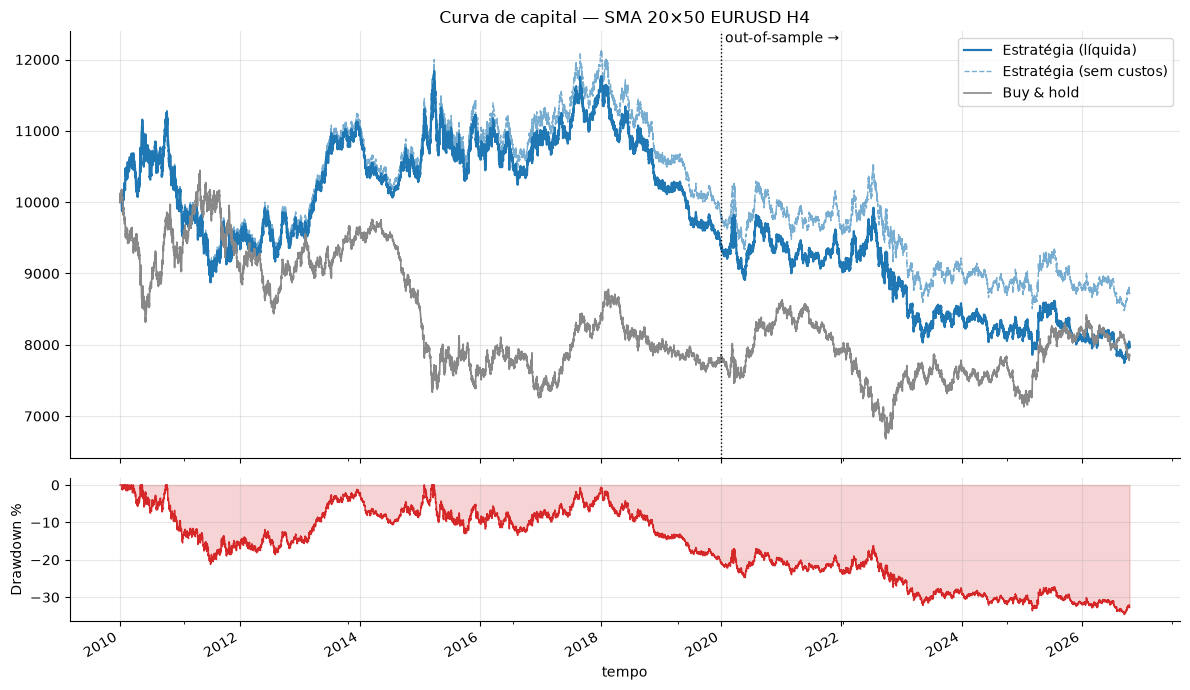

In [12]:
def curva(retornos, capital=CAPITAL_INICIAL):
    return capital * (1 + retornos).cumprod()


def drawdown(curva_capital):
    return curva_capital / curva_capital.cummax() - 1


df["capital"] = curva(df["ret_liquido"])
df["capital_bruto"] = curva(df["ret_bruto"])
df["capital_bh"] = curva(df["ret_mercado"])
df["dd"] = drawdown(df["capital"])

fig, (a1, a2) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
df["capital"].plot(ax=a1, color="#1f77b4", lw=1.6, label="Estratégia (líquida)")
df["capital_bruto"].plot(
    ax=a1, color="#1f77b4", lw=1, ls="--", alpha=0.6, label="Estratégia (sem custos)"
)
df["capital_bh"].plot(ax=a1, color="#888", lw=1.2, label="Buy & hold")
a1.axvline(pd.Timestamp(DATA_CORTE), color="k", ls=":", lw=1)
a1.text(pd.Timestamp(DATA_CORTE), a1.get_ylim()[1], " out-of-sample →", va="top")
a1.set_title(
    f"Curva de capital — SMA {MEDIA_RAPIDA}×{MEDIA_LENTA} {SIMBOLO} {TIMEFRAME}"
)
a1.legend()
(df["dd"] * 100).plot(ax=a2, color="#d62728", lw=1)
a2.fill_between(df.index, df["dd"] * 100, 0, color="#d62728", alpha=0.2)
a2.set_ylabel("Drawdown %")
plt.tight_layout()
plt.show()

## 7. Lista de operações
Agrupamos as barras consecutivas com a mesma posição: cada grupo é **uma operação**.
Para cada uma calculamos data de entrada e saída, direção, duração e resultado líquido (%).
É dessa tabela que saem win rate, payoff e expectativa.

586 operações | duração mediana: 36 barras (~6 dias)


,entrada,saida,direcao,barras,resultado
581,2026-08-14 04:00:00,2026-08-17 00:00:00,venda,6,-0.0038
582,2026-08-17 04:00:00,2026-08-28 16:00:00,compra,58,0.0004
583,2026-08-28 20:00:00,2026-09-08 00:00:00,venda,38,-0.0036
584,2026-09-08 04:00:00,2026-09-14 08:00:00,compra,26,-0.0078
585,2026-09-14 12:00:00,2026-10-16 16:00:00,venda,146,0.0278


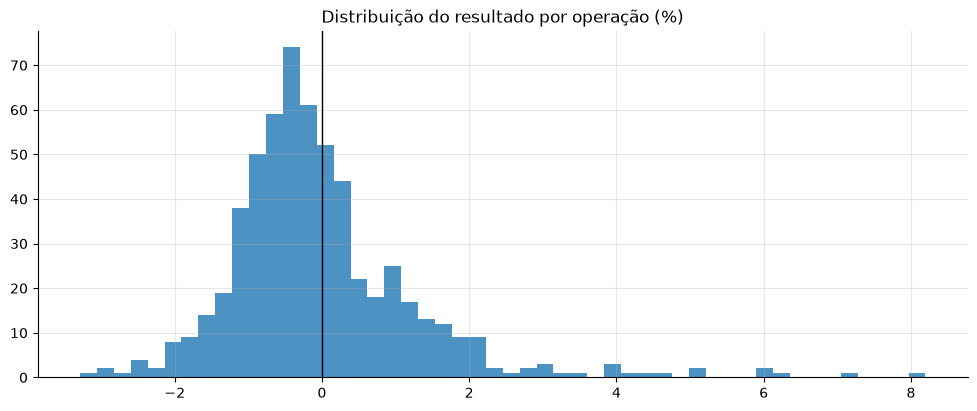

In [13]:
grupo = (df["posicao"] != df["posicao"].shift(1)).cumsum()
em_mercado = df["posicao"] != 0

trades = (
    df[em_mercado]
    .groupby(grupo[em_mercado])
    .agg(
        entrada=("posicao", lambda s: s.index[0]),
        saida=("posicao", lambda s: s.index[-1]),
        direcao=("posicao", "first"),
        barras=("posicao", "size"),
        resultado=("ret_liquido", lambda r: (1 + r).prod() - 1),
    )
    .reset_index(drop=True)
)
trades["direcao"] = trades["direcao"].map({1: "compra", -1: "venda"})

print(
    f"{len(trades)} operações | duração mediana: {trades['barras'].median():.0f} barras "
    f"(~{trades['barras'].median() * 4 / 24:.0f} dias)"
)
display(trades.tail(5))

ax = (trades["resultado"] * 100).hist(bins=50, color="#1f77b4", alpha=0.8)
ax.axvline(0, color="k", lw=1)
ax.set_title("Distribuição do resultado por operação (%)")
plt.show()

## 8. Métricas de desempenho
Uma função calcula tudo a partir dos retornos por barra e da lista de trades — vamos reutilizá-la
para comparar períodos e estratégias.

| Métrica | O que significa | Referência |
|---|---|---|
| **Retorno total / CAGR** | ganho no período / ganho médio por ano composto | maior é melhor |
| **Nº de trades** | quantas operações. Poucos trades = resultado pouco confiável | idealmente > 100 |
| **Win rate** | % de operações vencedoras | trend following costuma ficar em 30–45% |
| **Payoff** | ganho médio ÷ perda média | com win rate baixo, precisa ser > 1,5–2 |
| **Expectativa** | resultado médio por operação (%) | precisa ser > 0 *depois dos custos* |
| **Fator de lucro** | soma dos ganhos ÷ soma das perdas | > 1,3 já é interessante |
| **Máx. drawdown** | pior queda do topo ao fundo | quanto menor, melhor |
| **Sharpe** | retorno médio ÷ volatilidade, anualizado | > 1 bom; < 0,5 fraco |
| **Sortino** | igual ao Sharpe, mas só penaliza a volatilidade das quedas | > 1 bom |

Para anualizar usamos o número médio de barras por ano dos próprios dados (≈ 6 barras H4 por dia × ~260 dias).

In [14]:
BARRAS_ANO = len(df) / ((df.index[-1] - df.index[0]).days / 365.25)


def metricas(ret, trades_=None):
    # trades_=None -> sem lista de operações (ex.: buy & hold): métricas por trade ficam vazias
    if trades_ is None:
        trades_ = pd.DataFrame({"resultado": []})
    cap = (1 + ret).cumprod()
    anos = len(ret) / BARRAS_ANO
    ganhos = trades_.loc[trades_["resultado"] > 0, "resultado"]
    perdas = trades_.loc[trades_["resultado"] <= 0, "resultado"]
    neg = ret[ret < 0]
    return pd.Series(
        {
            "Retorno total %": (cap.iloc[-1] - 1) * 100,
            "CAGR %": (cap.iloc[-1] ** (1 / anos) - 1) * 100,
            "Nº trades": len(trades_) or np.nan,
            "Win rate %": len(ganhos) / len(trades_) * 100 if len(trades_) else np.nan,
            "Payoff": ganhos.mean() / abs(perdas.mean()) if len(perdas) else np.nan,
            "Expectativa %/trade": trades_["resultado"].mean() * 100,
            "Fator de lucro": ganhos.sum() / abs(perdas.sum())
            if len(perdas)
            else np.nan,
            "Máx. drawdown %": drawdown(cap).min() * 100,
            "Sharpe": ret.mean() / ret.std() * np.sqrt(BARRAS_ANO),
            "Sortino": ret.mean()
            / np.sqrt((neg**2).sum() / len(ret))
            * np.sqrt(BARRAS_ANO),
        }
    )


resumo = pd.DataFrame(
    {
        "Estratégia (líquida)": metricas(df["ret_liquido"], trades),
        "Estratégia (sem custos)": metricas(df["ret_bruto"]),
        "Buy & hold": metricas(df["ret_mercado"]),
    }
)
resumo.round(2)

,Estratégia (líquida),Estratégia (sem custos),Buy & hold
Retorno total %,-20.2300,-12.6700,-21.5100
CAGR %,-1.3400,-0.8000,-1.4300
Nº trades,586.0000,NaN,NaN
Win rate %,38.0500,NaN,NaN
Payoff,1.5200,NaN,NaN
Expectativa %/trade,-0.0300,NaN,NaN
Fator de lucro,0.9300,NaN,NaN
Máx. drawdown %,-34.5700,-30.0600,-36.0400
Sharpe,-0.1200,-0.0500,-0.1300
Sortino,-0.1700,-0.0800,-0.1800


**Como ler:** compare a coluna *líquida* com a *sem custos* — a diferença é o que a corretora leva.
Depois compare com o *buy & hold*: se a estratégia não supera nem ficar parado comprado (ou tem um
drawdown muito pior), ela não está agregando nada.

## 9. Baseline aleatório: a estratégia é melhor que a sorte?
Um resultado só tem valor se for **difícil de obter por acaso**. Criamos 300 estratégias "macaco":
cada uma vira de lado em datas **sorteadas**, com o **mesmo número de operações** e os **mesmos custos**
da nossa estratégia. Se a nossa ficar no meio da multidão de macacos, o resultado pode ser só sorte.

O **percentil** diz quantos % dos macacos ficaram abaixo da estratégia. Acima de 95% começa a ser
interessante; perto de 50% é indistinguível do acaso.

Retorno da estratégia: -20.2% | mediana dos aleatórios: -14.9%
A estratégia superou 41% das 300 estratégias aleatórias


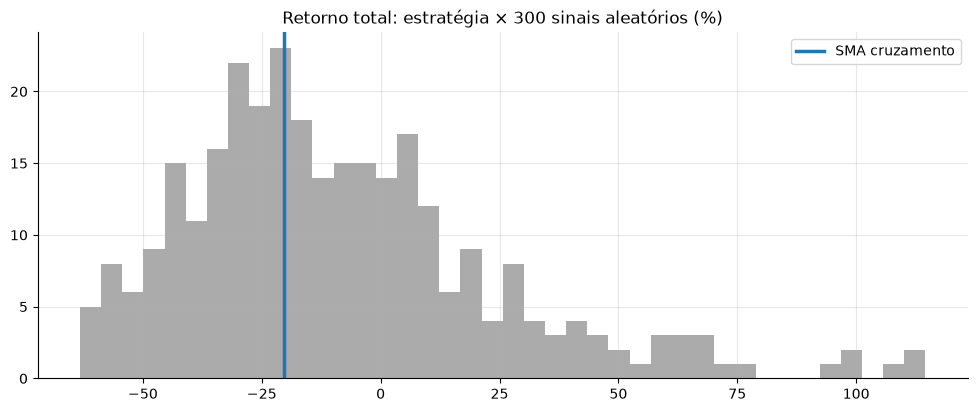

In [15]:
rng = np.random.default_rng(SEED)
N_SIM = 300
inicio = df.index.get_loc(
    df.index[df["posicao"] != 0][0]
)  # mesma barra de início da estratégia
ret_m = df["ret_mercado"].to_numpy()
custo_m = custo_pct.shift(1).fillna(0).to_numpy()
n = len(df)

finais = np.empty(N_SIM)
for i in range(N_SIM):
    viradas = np.sort(
        rng.choice(np.arange(inicio + 1, n), size=n_ops - 1, replace=False)
    )
    marcas = np.zeros(n)
    marcas[viradas] = 1
    pos = rng.choice([-1, 1]) * (-1) ** np.cumsum(marcas)
    pos[:inicio] = 0
    entradas = np.zeros(n, bool)
    entradas[viradas] = True
    entradas[inicio] = True
    r = pos * ret_m - np.where(entradas, custo_m, 0)
    finais[i] = (np.prod(1 + r) - 1) * 100

ret_estrategia = resumo.loc["Retorno total %", "Estratégia (líquida)"]
percentil = (finais < ret_estrategia).mean() * 100
print(
    f"Retorno da estratégia: {ret_estrategia:.1f}% | mediana dos aleatórios: {np.median(finais):.1f}%"
)
print(f"A estratégia superou {percentil:.0f}% das {N_SIM} estratégias aleatórias")

ax = pd.Series(finais).hist(bins=40, color="#888", alpha=0.7)
ax.axvline(ret_estrategia, color="#1f77b4", lw=2.5, label="SMA cruzamento")
ax.set_title("Retorno total: estratégia × 300 sinais aleatórios (%)")
ax.legend()
plt.show()

## 10. In-sample × out-of-sample
Até aqui olhamos o período inteiro. Mas se você **escolheu** as médias 20/50 olhando esse gráfico,
o resultado está contaminado: é fácil achar parâmetros que funcionaram no passado.

A defesa é dividir os dados:
- **In-sample (IS)**: período de estudo, onde você pode explorar e ajustar (até `DATA_CORTE`).
- **Out-of-sample (OOS)**: período "guardado na gaveta", que só é usado **uma vez**, para validar.

Se a estratégia é robusta, as métricas nos dois períodos devem ser parecidas. Se o OOS desaba,
o resultado do IS provavelmente era sorte ou *overfitting*.

> O passo profissional seguinte é o **walk-forward**: otimizar numa janela, testar na seguinte,
> andar a janela e repetir. Fica para um próximo notebook.

In [16]:
corte = pd.Timestamp(DATA_CORTE)
is_ = df.index < corte
comparacao = pd.DataFrame(
    {
        f"In-sample (até {DATA_CORTE[:4]})": metricas(
            df.loc[is_, "ret_liquido"], trades[trades["entrada"] < corte]
        ),
        f"Out-of-sample (desde {DATA_CORTE[:4]})": metricas(
            df.loc[~is_, "ret_liquido"], trades[trades["entrada"] >= corte]
        ),
        "Buy & hold OOS": metricas(df.loc[~is_, "ret_mercado"]),
    }
)
comparacao.round(2)

,In-sample (até 2020),Out-of-sample (desde 2020),Buy & hold OOS
Retorno total %,-5.9100,-15.2200,-0.0800
CAGR %,-0.6100,-2.4000,-0.0100
Nº trades,331.0000,255.0000,NaN
Win rate %,38.3700,37.6500,NaN
Payoff,1.5700,1.4400,NaN
Expectativa %/trade,-0.0100,-0.0600,NaN
Fator de lucro,0.9800,0.8700,NaN
Máx. drawdown %,-21.1900,-21.9400,-22.6000
Sharpe,-0.0200,-0.2800,0.0400
Sortino,-0.0300,-0.4000,0.0500


## 11. Sensibilidade dos parâmetros (só no in-sample)
Uma estratégia robusta não deve depender de um número mágico. Testamos uma **grade pequena** de médias
**apenas no período in-sample** e olhamos o Sharpe líquido de cada combinação.

- **Bom sinal:** uma "região" ampla de combinações razoáveis (cores parecidas lado a lado).
- **Mau sinal:** só uma célula isolada brilhando — isso é sorte, não estratégia.

A função `backtest()` abaixo repete os passos 3–5 de forma compacta, para poder rodar várias vezes.

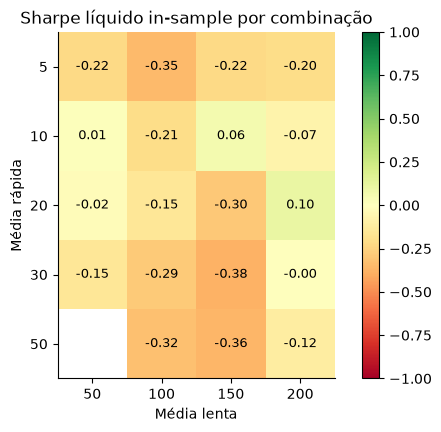

Melhor combinação IS: SMA 20x200 (Sharpe 0.10) | combinações com Sharpe > 0: 3 de 19


In [17]:
def backtest(dados, rapida, lenta):
    mr = dados["fechamento"].rolling(rapida).mean()
    ml = dados["fechamento"].rolling(lenta).mean()
    sinal = pd.Series(np.where(mr > ml, 1, -1), index=dados.index).where(ml.notna(), 0)
    pos = sinal.shift(1).fillna(0)
    entrada = (pos != pos.shift(1)) & (pos != 0)
    c = (
        (dados["spread"] + 2 * SLIPPAGE_PONTOS) * PONTO / dados["fechamento"]
        + COMISSAO_PCT / 100
    ).shift(1)
    return pos * dados["fechamento"].pct_change().fillna(0) - np.where(
        entrada, c, 0
    ), int(entrada.sum())


dados_is = df.loc[is_]
rapidas, lentas = [5, 10, 20, 30, 50], [50, 100, 150, 200]
sharpe = pd.DataFrame(index=rapidas, columns=lentas, dtype=float)
for r in rapidas:
    for l in lentas:
        if r >= l:  # rápida precisa ser menor que a lenta
            continue
        ret, _ = backtest(dados_is, r, l)
        sharpe.loc[r, l] = ret.mean() / ret.std() * np.sqrt(BARRAS_ANO)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.grid(False)
im = ax.imshow(sharpe.values, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(lentas)), lentas)
ax.set_yticks(range(len(rapidas)), rapidas)
ax.set_xlabel("Média lenta")
ax.set_ylabel("Média rápida")
for i in range(len(rapidas)):
    for j in range(len(lentas)):
        if pd.notna(sharpe.iat[i, j]):
            ax.text(
                j, i, f"{sharpe.iat[i, j]:.2f}", ha="center", va="center", fontsize=9
            )
ax.set_title("Sharpe líquido in-sample por combinação")
fig.colorbar(im)
plt.show()

melhor = sharpe.stack().idxmax()
print(
    f"Melhor combinação IS: SMA {melhor[0]}x{melhor[1]} (Sharpe {sharpe.stack().max():.2f}) | "
    f"combinações com Sharpe > 0: {(sharpe > 0).sum().sum()} de {sharpe.notna().sum().sum()}"
)

## 12. Salvar os resultados
Cada backtest ganha uma pasta em `backtests/` com um **ID** e os parâmetros no nome
(ex.: `001_sma20x50_EURUSD_H4`). Lá ficam os números em arquivos simples, para comparar testes depois:

- `parametros.json` — a configuração exata usada (para reproduzir);
- `metricas.csv` — período completo, in-sample e out-of-sample;
- `trades.csv` — todas as operações;
- `sensibilidade_sharpe_is.csv` — o mapa de calor em tabela.

Ao testar uma variação, mude `BACKTEST_ID` para não sobrescrever o teste anterior.

In [ ]:
import json

BACKTEST_ID = "001"
PASTA_BACKTEST = Path("..") / "backtests" / f"{BACKTEST_ID}_sma{MEDIA_RAPIDA}x{MEDIA_LENTA}_{SIMBOLO}_{TIMEFRAME}"
PASTA_BACKTEST.mkdir(parents=True, exist_ok=True)

parametros = {"id": BACKTEST_ID, "simbolo": SIMBOLO, "timeframe": TIMEFRAME,
              "media_rapida": MEDIA_RAPIDA, "media_lenta": MEDIA_LENTA,
              "slippage_pontos": SLIPPAGE_PONTOS, "comissao_pct": COMISSAO_PCT,
              "data_inicio": DATA_INICIO, "data_corte": DATA_CORTE,
              "dados_ate": f"{df.index[-1]:%Y-%m-%d}", "seed": SEED,
              "percentil_vs_aleatorio": round(float(percentil), 1)}
(PASTA_BACKTEST / "parametros.json").write_text(json.dumps(parametros, indent=2, ensure_ascii=False), encoding="utf-8")
pd.concat([resumo, comparacao], axis=1).round(4).to_csv(PASTA_BACKTEST / "metricas.csv", encoding="utf-8")
trades.to_csv(PASTA_BACKTEST / "trades.csv", index=False, encoding="utf-8")
sharpe.round(4).to_csv(PASTA_BACKTEST / "sensibilidade_sharpe_is.csv", encoding="utf-8")
print(f"Resultados salvos em {PASTA_BACKTEST.resolve()}")

## 13. Conclusões e próximos passos

### O que encontramos (rodada de 17/10/2026 — EURUSD H4, 2010 → out/2026, SMA 20×50)
| | Estratégia (líquida) | Sem custos | Buy & hold |
|---|---|---|---|
| Retorno total | −20,2% | −12,7% | −21,5% |
| Sharpe | −0,12 | −0,05 | −0,13 |
| Máx. drawdown | −34,6% | −30,1% | −36,0% |

- **586 operações**, win rate de **38%**, payoff de **1,52**, fator de lucro de **0,93**: o perfil típico de
  seguidor de tendência (perde muitas vezes e ganha mais quando acerta), mas o payoff **não compensou** o win rate.
- **Custos:** cerca de 0,015% por operação parece pouco, mas em 586 operações somaram **~9% do capital** e
  levaram um resultado que já era levemente negativo para −20%.
- **Contra o acaso:** a estratégia ficou no **percentil ~41** dos sinais aleatórios, ou seja, **não se distingue de sorte**.
- **IS × OOS:** negativa nos dois períodos (Sharpe −0,02 no in-sample e −0,28 no out-of-sample). Pelo menos é coerente: não há um "passado bom" que nos engane.
- **Sensibilidade:** só **3 de 19** combinações de médias tiveram Sharpe positivo no in-sample, e a melhor
  (20×200) teve Sharpe de apenas 0,10. Não existe uma região robusta.

**Veredito:** o cruzamento simples de médias **não tem vantagem** no EURUSD H4 desde 2010. Esse é um
resultado **válido e útil**: o backtest fez o trabalho dele e barrou uma ideia ruim antes de ela custar dinheiro.
O EURUSD passou boa parte desse período lateral/em faixa, que é o pior cenário para seguidor de tendência.

> Os números acima mudam conforme os dados forem atualizados. Ao rodar de novo, confira as tabelas.

### Roteiro de leitura para qualquer backtest

1. **Custos:** quanto a curva *sem custos* se afasta da *líquida*? Em timeframes menores (M15, M5)
   o custo come muito mais, porque há mais operações.
2. **Baseline:** a estratégia superou o buy & hold? Ficou acima do percentil 95 dos sinais aleatórios?
3. **Estabilidade:** o out-of-sample se parece com o in-sample, ou desabou?
4. **Robustez:** o mapa de calor mostra uma região boa ampla ou uma célula isolada?
5. **Perfil:** win rate baixo + payoff alto é o normal de seguidor de tendência. Você aguentaria
   psicologicamente o máximo drawdown e as sequências de perdas?

> **Regra de ouro:** se a estratégia não passa nos itens 2 e 3, ela **não vai para conta real**
> — nem para a demo — antes de ser melhorada.

### Exercícios
1. Troque `TIMEFRAME` para `"D1"` e depois `"H1"`. O que acontece com o nº de trades e o efeito dos custos?
2. Troque `SIMBOLO` para `"GBPUSD"` ou `"USDJPY"` (sem mudar as médias). A estratégia se generaliza?
3. Coloque `SLIPPAGE_PONTOS = 10`. A estratégia sobrevive a uma execução ruim?
4. Faça uma versão **só comprada** (troque `-1` por `0` no sinal). Melhora ou piora?
5. Escolha a melhor célula do mapa de calor e rode o notebook com ela. Ela também é boa no out-of-sample?